# Finding pairs with unsupervised learning
### EUTIC Quant final project: PCA + clustering for pairs selection

Based on Sarmento & Horta, *Enhancing a Pairs Trading strategy with the application of Machine Learning* (Section III).

**The problem.** The pairs trading notebook showed that KO/PEP, the textbook pair, fails the cointegration test and has no edge left: everyone trades it. To find pairs other people haven't, we have two naive options:

| Search method | Problem |
|---|---|
| Test **every** possible pair | With $N$ assets there are $N(N-1)/2$ pairs. At a 5% significance level, about 1 in 20 unrelated pairs passes by luck: **spurious pairs**. |
| Test only pairs in the **same sector** | Fewer false positives, but we only find the obvious pairs everyone else finds. |

**The idea.** Let the data decide which assets belong together:

1. **PCA**: describe each ETF by a handful of numbers (how it reacts to the main hidden "risk factors").
2. **Clustering**: group ETFs whose descriptions are similar. Only search for pairs *inside* a cluster.
3. **Filters**: keep only pairs that are cointegrated, mean-reverting, revert at a tradeable speed, and cross their mean often.

We compare four ways of searching: **all pairs**, **same category**, **K-means clusters** and **OPTICS clusters**.

**Today (Sunday): run Parts 0 to 4.** Part 5 (the filters) is for Tuesday.

## Part 0. Parameters

Everything you might want to change lives in this cell.

**Time windows** (same structure as the paper):
- **Formation** 2020 to 2022: we find clusters and pairs using *only* this data.
- **Validation** 2023 and **Test** 2024: used on Friday for the backtest. Nothing in this notebook looks at them, which is how we avoid **look-ahead bias**.

**Universe.** Commodity-linked ETFs, each labelled with a category (like the paper's 5 categories), plus a few "outsiders" that are *not* commodity funds. If clustering works, the outsiders should mostly end up as noise or in their own group.

We chose ETFs since they are more stable since they are like a basket of many companies/commodities, hence the relationship between two pairs of ETFs are less likely to break if for example a publicly traded company suddenly tanked and shut down. 

Any ticker that doesn't exist, has gaps, or is too illiquid is dropped automatically in Part 1, so you don't need to check each one by hand.

In [23]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, OPTICS, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

# ---- Time windows ----
DATA_START, DATA_END = "2020-01-01", "2025-01-01"      # yfinance end date is exclusive
FORMATION = ("2020-01-01", "2022-12-31")               # clusters + pairs found here only

# ---- Universe: ticker -> category ----
UNIVERSE = {
    # Energy
    "XLE": "Energy", "VDE": "Energy", "XOP": "Energy", "OIH": "Energy", "FCG": "Energy",
    "IXC": "Energy", "IEO": "Energy", "XES": "Energy", "IEZ": "Energy",
    "USO": "Energy", "BNO": "Energy", "UNG": "Energy", "AMLP": "Energy",
    "URA": "Energy", "URNM": "Energy",
    # Precious metals (GLD/IAU and SLV/SIVR are deliberate duplicates: a sanity check)
    "GLD": "Precious metals", "IAU": "Precious metals", "SLV": "Precious metals",
    "SIVR": "Precious metals", "PPLT": "Precious metals", "PALL": "Precious metals",
    "GDX": "Precious metals", "GDXJ": "Precious metals", "SIL": "Precious metals",
    "RING": "Precious metals",
    # Industrial metals
    "XME": "Industrial metals", "COPX": "Industrial metals", "CPER": "Industrial metals",
    "PICK": "Industrial metals", "LIT": "Industrial metals", "REMX": "Industrial metals",
    "DBB": "Industrial metals", "SLX": "Industrial metals",
    # Agriculture
    "DBA": "Agriculture", "CORN": "Agriculture", "WEAT": "Agriculture",
    "SOYB": "Agriculture", "MOO": "Agriculture",
    # Broad commodities
    "DBC": "Broad commodities", "GSG": "Broad commodities", "PDBC": "Broad commodities",
    "COMT": "Broad commodities",
    # Outsiders: not commodity funds
    "SPY": "Outsider", "TLT": "Outsider", "XLK": "Outsider", "XLU": "Outsider",
    "XLV": "Outsider", "XLB": "Outsider",
}

MIN_DOLLAR_VOLUME = 1e6     # average daily $ traded in the formation window
MAX_MISSING_DAYS = 5        # tolerate a few gaps (filled forward), drop anything worse

N_COMPONENTS = 5            # PCA dimensions per ETF (the paper uses 5)
OPTICS_MIN_SAMPLES = 3      # smallest group OPTICS will call a cluster
RANDOM_STATE = 0            # makes K-means and t-SNE reproducible

# Colours: one fixed colour per category, used in every chart
CATEGORY_COLORS = {
    "Energy": "#2a78d6", "Precious metals": "#eb6834", "Industrial metals": "#1baf7a",
    "Agriculture": "#eda100", "Broad commodities": "#e87ba4", "Outsider": "#6250d6",
}
NOISE_COLOR = "#b4b2a9"

print(f"{len(UNIVERSE)} tickers in the starting universe")

48 tickers in the starting universe


## Part 1. Data

We download daily adjusted prices and volumes once and **save them to CSV**. yfinance is an unofficial API and can block you if you download repeatedly, and a saved file means both of you work from identical data. To re-download (e.g. after changing the universe), delete the two CSV files.

Then we clean the universe:
1. **Gaps.** Drop ETFs missing more than a few days anywhere in 2020 to 2024 (usually: launched too late, or closed). The backtest on Friday needs them to exist in the test year too.
2. **Liquidity.** Drop ETFs that trade less than `MIN_DOLLAR_VOLUME` per day. Illiquid funds are expensive to trade, so a backtest on them would be too optimistic.

In [24]:
PRICE_FILE, VOLUME_FILE = "etf_prices.csv", "etf_volumes.csv"

if os.path.exists(PRICE_FILE) and os.path.exists(VOLUME_FILE):
    prices = pd.read_csv(PRICE_FILE, index_col=0, parse_dates=True)
    volumes = pd.read_csv(VOLUME_FILE, index_col=0, parse_dates=True)
    print("Loaded saved data.")
else:
    raw = yf.download(list(UNIVERSE), start=DATA_START, end=DATA_END,
                      auto_adjust=True, progress=False)
    prices, volumes = raw["Close"], raw["Volume"]
    prices.to_csv(PRICE_FILE); volumes.to_csv(VOLUME_FILE)
    print("Downloaded and saved data.")

print(f"Shape: {prices.shape[0]} days x {prices.shape[1]} ETFs")

Loaded saved data.
Shape: 1258 days x 48 ETFs


In [25]:
# 1. Gaps: count missing days per ETF over the whole period
missing = prices.isna().sum()
too_gappy = missing[missing > MAX_MISSING_DAYS].index.tolist()

# 2. Liquidity: average daily dollar volume in the formation window
form_slice = slice(*FORMATION)
dollar_vol = (prices.loc[form_slice] * volumes.loc[form_slice]).mean()
too_illiquid = dollar_vol[dollar_vol < MIN_DOLLAR_VOLUME].index.difference(too_gappy).tolist()

keep = [t for t in prices.columns if t not in too_gappy + too_illiquid]
prices = prices[keep].ffill().dropna()        # fill the few small gaps forward

print(f"Dropped for gaps ({len(too_gappy)}):      {too_gappy}")
print(f"Dropped as illiquid ({len(too_illiquid)}): {too_illiquid}")
print(f"\nKept {len(keep)} ETFs:")
categories = pd.Series({t: UNIVERSE[t] for t in keep}, name="category")
print(categories.value_counts().to_string())

Dropped for gaps (0):      []
Dropped as illiquid (0): []

Kept 48 ETFs:
category
Energy               15
Precious metals      10
Industrial metals     8
Outsider              6
Agriculture           5
Broad commodities     4


## Part 2. PCA: a short description of each ETF

To learn about PCA in greater detail, watch this video: https://www.youtube.com/watch?v=HZl32cDhWEM

**Why returns, not prices?** Almost every price series trends upwards or downwards over three years, so two unrelated ETFs can look "similar" just because both trended. Daily returns, $R_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}$, remove the trend and leave how each ETF actually *moves* day to day.

**What PCA does here.** Our returns form a table with ~750 rows (days) and ~45 columns (ETFs). PCA finds a small number of hidden patterns, the **principal components**, that explain most of the day-to-day movement across all ETFs at once. You can think of each one as a **risk factor**:
- Component 1 is usually "the whole market / all commodities moved together today".
- Later components are things like "oil up, gold down" or "metals vs everything else".

Each ETF gets a **loading** on each component: how strongly it reacts to that factor. With 5 components, each ETF is now described by **5 numbers** instead of 750 returns. Two ETFs with similar loadings react to the world in similar ways, which is exactly what we want a pair to do.

**Why only 5?** Clustering works badly in many dimensions (the *curse of dimensionality*: in high dimensions, every point ends up roughly equally far from every other). The paper keeps it below 15 and found 5 worked as well as anything higher.

We **standardise** each ETF's returns first (mean 0, standard deviation 1), so a very volatile ETF doesn't dominate the components just because its numbers are bigger.

In [26]:
returns = prices.loc[form_slice].pct_change().dropna()        # formation window only
returns_std = StandardScaler().fit_transform(returns)         # each ETF: mean 0, std 1

pca = PCA(n_components=N_COMPONENTS).fit(returns_std)

# Each ETF's loadings on the components: one row per ETF, one column per component
features = pd.DataFrame(pca.components_.T, index=returns.columns,
                        columns=[f"PC{k+1}" for k in range(N_COMPONENTS)])

explained = pca.explained_variance_ratio_
print("Share of daily movement explained by each component:")
for k, e in enumerate(explained):
    print(f"  PC{k+1}: {e:6.1%}")
print(f"  Total: {explained.sum():6.1%}")

features.round(3).head(8)

Share of daily movement explained by each component:
  PC1:  46.3%
  PC2:  12.5%
  PC3:   9.0%
  PC4:   4.9%
  PC5:   3.4%
  Total:  76.2%


,PC1,PC2,PC3,PC4,PC5
AMLP,0.161,-0.124,-0.019,-0.139,-0.100
BNO,0.139,-0.102,0.225,-0.078,0.339
COMT,0.151,-0.034,0.263,0.009,0.210
COPX,0.182,0.036,-0.089,0.129,-0.005
CORN,0.067,-0.000,0.252,0.322,-0.288
CPER,0.136,0.056,0.034,0.149,0.038
DBA,0.110,0.009,0.220,0.313,-0.211
DBB,0.124,0.056,0.099,0.135,0.067


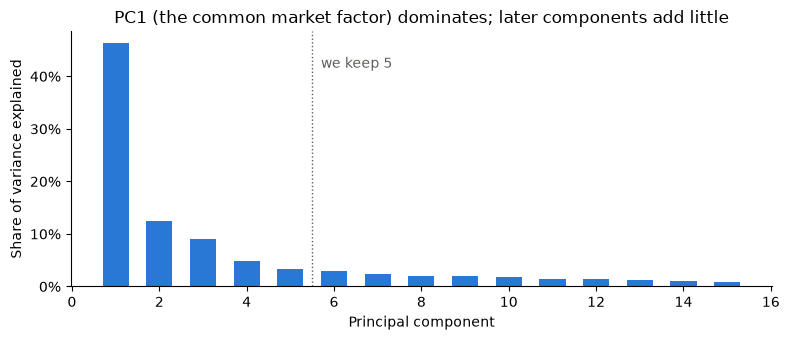

In [27]:
# How much does each extra component add? (shows why a few components are enough)
full = PCA().fit(returns_std).explained_variance_ratio_[:15]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(1, len(full) + 1), full, color="#2a78d6", width=0.6)
ax.axvline(N_COMPONENTS + 0.5, color="#5f5e5a", ls=":", lw=1)
ax.text(N_COMPONENTS + 0.7, full.max() * 0.9, f"we keep {N_COMPONENTS}", color="#5f5e5a")
ax.set_xlabel("Principal component"); ax.set_ylabel("Share of variance explained")
ax.set_title("PC1 (the common market factor) dominates; later components add little")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Part 3. Clustering

We now have one point per ETF in 5-dimensional space. It inherently clusters groups that behave alike but we can use different clustering methods to identify smaller groups that we can use to cut down the search from every possible pair to pairs within groups.

### 3a. K-means (the method most people know)

K-means picks $k$ centres at random and assigns every point to its nearest centre. It then moves each centre to the average of its points, and repeats the process until nothing changes. The result is $k$ clusters with every point inside a cluster.

Its problems for our use case:
1. **We must choose $k$** in advance. Here we try $k = 2$ to $15$ and pick the one with the best **silhouette score** (a measure from −1 to 1 of how much closer each point is to its own cluster than to the next one). This introduces bias.
2. **Every ETF is forced into a cluster**, even outliers that don't really belong anywhere. That brings in pairs we don't want.
3. **It assumes round, similar-sized clusters** which can cause us to lose good pairs. By putting each point with its nearest centroid, it builds a preference for round, compact clusters of similar size, when in reality, real stock groups rarely look like that.

In [28]:
X = features.values #the table from the PCA step, containing each ETF and their corresponding loadings on PC1 to PC5

#optimising the number of clusters using silhouette score
sil = {} 
for k in range(2, 16):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    sil[k] = silhouette_score(X, labels_k)

best_k = max(sil, key=sil.get)
kmeans_labels = KMeans(n_clusters=best_k, n_init=10,
                       random_state=RANDOM_STATE).fit_predict(X)

print("Silhouette score by k:", {k: round(v, 3) for k, v in sil.items()})
print(f"\nBest k = {best_k}. Every one of the {len(X)} ETFs is assigned to a cluster.")

Silhouette score by k: {2: 0.277, 3: 0.406, 4: 0.532, 5: 0.637, 6: 0.602, 7: 0.61, 8: 0.597, 9: 0.591, 10: 0.599, 11: 0.596, 12: 0.576, 13: 0.59, 14: 0.578, 15: 0.505}

Best k = 5. Every one of the 48 ETFs is assigned to a cluster.


### Silhouette Score

This measures how well separated and cohesive the clusters are. The value ranges from -1 to 1.

**How is it calculated**

For each data point, $i$, the silhouette score combines two values:
1. **Cohesion**: the average distance from the point $i$ to all other points within its cluster.
2. **Separation**: the average distance from point $i$ to all the points in its nearest neighbouring cluster.

$$ S(i) = \frac{b(i)-a(i)}{\operatorname{max}(a(i),b(i))}$$

The closer the silhouette score is to 1, the better matched the point is to its own cluster.


### 3b. DBSCAN (Density Based Spatial Clustering of Applications with Noise)

DBSCAN is a one-up on K-means in that it clusters based on point density, introducing outliers as a possibility. Additionally, it doesn't require us to choose a number of clusters, $k$, and clusters can be any shape.

To begin, we must set two parameters: **$\varepsilon$** (a maximum distance between two points for them to be considered neighbours), and **MinPts** (the number of points required to form a dense region, including itself). 

**How does it choose $\varepsilon$?**
For each ETF we measure the distance to its MinPts-th nearest neighbour (counting itself). Sorted, these distances stay flat for ETFs inside dense groups, then shoot up for isolated ones. We set ε at the elbow, so ETFs in dense groups become core points and isolated ones become noise. (see the 2nd code cell for what this looks like)

Using the values of $\varepsilon$ and MinPts, the algorithm visits each point, and categorises them as one of: core points, border points and noise points. 
Conditions for categorisation:
1. Core point: if it has at least MinPts points inside its radius of $\varepsilon$
2. Border point: if (a) it's not a core point/has fewer than MinPts within its $\varepsilon$-neighbourhood (b) it is within $\varepsilon$ distance of one or more core points.
3. Noise point: neither a core nor border point.

In order to cluster points, it evaluates which points are density reachable. A point P is directly density reachable from Q if P in within the $\varepsilon$-neighbourhood of Q, and Q is a core point. P itself can be a core or border point.

Using this, the algorithm creates a chain of directly density reachable points (this includes core and border points) that creates one "cluster". 

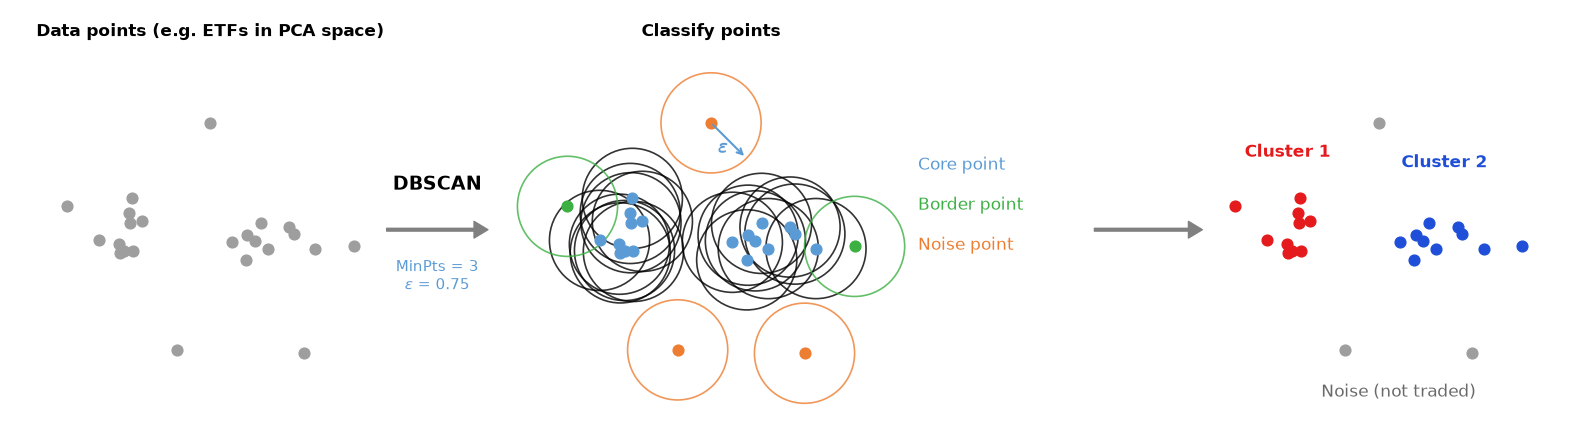

In [29]:
#DBSCAN clustering algorithm visual representation
EPS, MIN_PTS = 0.75, 3

rng = np.random.default_rng(7)
blob1 = rng.normal([1.0, 2.0], 0.35, size=(9, 2))
blob2 = rng.normal([3.4, 2.0], 0.35, size=(9, 2))
border = np.array([[0.05, 2.35], [4.35, 1.75]])           # edge points -> border
noise = np.array([[2.2, 3.6], [1.7, 0.2], [3.6, 0.15]])   # isolated -> noise
X = np.vstack([blob1, blob2, border, noise])

db = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit(X)
labels = db.labels_
is_core = np.zeros(len(X), bool)
is_core[db.core_sample_indices_] = True
is_noise = labels == -1
is_border = ~is_core & ~is_noise



#diagram generation
GREY, CORE, BORDER, NOISE = "#9e9e9e", "#5b9bd5", "#3cb043", "#ed7d31"
CLUSTER_COLS = ["#e41a1c", "#1f4fd8", "#7b3294", "#008837"]
SHIFT = 7.5  # horizontal gap between the three panels

fig, ax = plt.subplots(figsize=(16, 4.8))
ax.set_aspect("equal")
ax.axis("off")

# Panel 1: raw data
ax.scatter(X[:, 0], X[:, 1], s=60, c=GREY, zorder=3)
ax.text(2.2, 4.9, "Data points (e.g. ETFs in PCA space)", ha="center", fontsize=12, weight="bold")

# Panel 2: eps-neighbourhoods and point types
off = SHIFT
for i, (x, y) in enumerate(X):
    if is_core[i]:
        edge, fill = "black", CORE
    elif is_border[i]:
        edge, fill = BORDER, BORDER
    else:
        edge, fill = NOISE, NOISE
    ax.add_patch(Circle((x + off, y), EPS, fill=False, ec=edge, lw=1.2, alpha=0.8, zorder=1))
    ax.scatter(x + off, y, s=60, c=fill, zorder=3)

# eps radius annotation on one noise point
nx, ny = X[is_noise][0]
ax.annotate("", xy=(nx + off + EPS * 0.7, ny - EPS * 0.7), xytext=(nx + off, ny),
            arrowprops=dict(arrowstyle="->", color=CORE, lw=1.5))
ax.text(nx + off + 0.1, ny - 0.45, r"$\varepsilon$", color=CORE, fontsize=14)

ax.text(2.2 + off, 4.9, "Classify points", ha="center", fontsize=12, weight="bold")
ax.text(5.3 + off, 2.9, "Core point", color=CORE, fontsize=12)
ax.text(5.3 + off, 2.3, "Border point", color=BORDER, fontsize=12)
ax.text(5.3 + off, 1.7, "Noise point", color=NOISE, fontsize=12)

# Panel 3: final clusters
off = 2 * SHIFT + 2.5
for k in sorted(set(labels) - {-1}):
    m = labels == k
    ax.scatter(X[m, 0] + off, X[m, 1], s=60, c=CLUSTER_COLS[k % len(CLUSTER_COLS)], zorder=3)
    cx, cy = X[m].mean(axis=0)
    ax.text(cx + off, cy + 1.1, f"Cluster {k + 1}", ha="center", fontsize=12,
            color=CLUSTER_COLS[k % len(CLUSTER_COLS)], weight="bold")
ax.scatter(X[is_noise, 0] + off, X[is_noise, 1], s=60, c=GREY, zorder=3)
ax.text(X[is_noise, 0].mean() + off, -0.5, "Noise (not traded)", ha="center", fontsize=12, color="dimgrey")

# Arrows between panels
arrow = dict(arrowstyle="simple,head_width=1.2,head_length=1", fc="grey", ec="grey")
ax.annotate("", xy=(SHIFT - 1.1, 2.0), xytext=(4.8, 2.0), arrowprops=arrow)
ax.text((4.8 + SHIFT - 1.1) / 2, 2.6, "DBSCAN", ha="center", fontsize=14, weight="bold")
ax.text((4.8 + SHIFT - 1.1) / 2, 1.1, f"MinPts = {MIN_PTS}\n" + rf"$\varepsilon$ = {EPS}",
        ha="center", fontsize=11, color=CORE)
ax.annotate("", xy=(2 * SHIFT + 2.1, 2.0), xytext=(2 * SHIFT + 0.4, 2.0), arrowprops=arrow)

ax.set_xlim(-0.8, 2 * SHIFT + 7.5)
ax.set_ylim(-1.0, 5.3)
plt.tight_layout()
plt.show()


Now lets cluster our ETFs using DBSCAN.

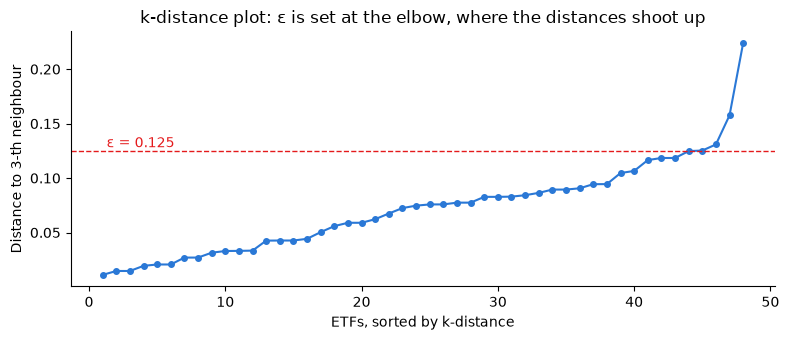

DBSCAN (ε = 0.125, MinPts = 3) found 6 clusters and left 2 of 48 ETFs as noise.


In [30]:
from sklearn.neighbors import NearestNeighbors

X = features.values          # reset X: the DBSCAN diagram cell above reuses X for its toy points
DBSCAN_MIN_SAMPLES = OPTICS_MIN_SAMPLES     # same MinPts as OPTICS so the comparison is fair

# Choosing eps with the k-distance plot
nn = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(X)
k_dist = np.sort(nn.kneighbors(X)[0][:, -1])     # distance to each ETF's MinPts-th neighbour (itself included)

x_norm = np.linspace(0, 1, len(k_dist))
y_norm = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
dbscan_eps = k_dist[np.argmax(x_norm - y_norm)]  # elbow: furthest below the line from first to last point
# dbscan_eps = 0.10                              # <- or set by hand after looking at the plot

dbscan = DBSCAN(eps=dbscan_eps, min_samples=DBSCAN_MIN_SAMPLES).fit(X)
dbscan_labels = dbscan.labels_
dbscan_n_clusters = dbscan_labels.max() + 1
dbscan_n_noise = (dbscan_labels == -1).sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(k_dist) + 1), k_dist, marker="o", ms=4, color="#2a78d6")
ax.axhline(dbscan_eps, color="#e41a1c", ls="--", lw=1)
ax.text(1, dbscan_eps, f" ε = {dbscan_eps:.3f}", color="#e41a1c", va="bottom")
ax.set_xlabel("ETFs, sorted by k-distance")
ax.set_ylabel(f"Distance to {DBSCAN_MIN_SAMPLES}-th neighbour")
ax.set_title("k-distance plot: ε is set at the elbow, where the distances shoot up")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"DBSCAN (ε = {dbscan_eps:.3f}, MinPts = {DBSCAN_MIN_SAMPLES}) found {dbscan_n_clusters} clusters "
      f"and left {dbscan_n_noise} of {len(X)} ETFs as noise.")

### 3b. OPTICS (Ordering Points To Identify Clustering Structure)
DBSCAN's weakness: one fixed $\varepsilon$. If one group of ETFs is very tightly packed and another more loosely, no single $\varepsilon$ finds both (Fig. 1 in the paper).

**OPTICS** fixes this. It effectively tries every $\varepsilon$ at once, so we only set *minPts* (`OPTICS_MIN_SAMPLES`). Noise points get the label **−1**.

In [31]:
optics = OPTICS(min_samples=OPTICS_MIN_SAMPLES).fit(X)
optics_labels = optics.labels_

n_clusters = optics_labels.max() + 1
n_noise = (optics_labels == -1).sum()
print(f"OPTICS found {n_clusters} clusters and left {n_noise} of {len(X)} ETFs as noise.")

OPTICS found 10 clusters and left 5 of 48 ETFs as noise.


# How does OPTICS indentify clusters?

**The reachability plot** is how OPTICS finds clusters.

OPTICS visits the points in a special order (moving from current point $p$ to the point with the lowest reachability $o$. In other words, the lowest reachability is just the next closest point. Hence this makes it go through an entire crowded region before jumping to the next), and for each one plots how far it is from the dense region before it. 

### How does it create a priority queue to find the reachability plot?
OPTICS starts at some arbitrary point, p. At point p, it calculates the reachability of it's neighbours, $o$, with the following formula:
$$\text{reachability}(o, p)=max(\text{core distance}(p), \text{distance}(p, o))$$
$p$ is the current active point, or the point that OPTICS is currently visiting.   \
$o$ are the unprocessed points that are neighbours of $p$.   \
Core distance of $p$: the distance from p to its min_samples-th nearest neighbour. It measures how crowded the area around p is. A small value means p is in a dense spot. In sklearn, p counts as its own first neighbour, and in our code, we set the core distance to min_samples=3, which is the distance to p’s 2nd-closest other ETF.    \
Reach distance: the maximum distance from (a point to) the centre.  \
distance: the distance from the neightbour $o$ to $p$.

Then, it puts each point into the priority queue in order of lowest to highest reachability. the points $o$ are the neighbours of $p$, however since there is no maximum distance for a point to be considered a neighbour, all points are neighbours of $p$. 
After visiting $p$,  it  jumps to the point that is first in queue (w/ lowest reachability), from this new point, which is the new $p$, it recomputes the reachability of all of it's unvisited neighbours, and if the new reachability of any point $o$ is less than the current reachability stored in the priority queue, the value is updated. Once all the values are updated, the queue is rearranged from lowest to highest reachability, and the process is repeated. When a point comes off the front of the queue, its reachability at that moment is fixed and becomes its bar in the reachability plot. The order points come off the queue is the x-axis.
In the plot below, each bar represents the smallest reachability distance from any point it had visited earlier. Short bars mean that the ETFs are close together, and peaks represent gaps. This makes **valleys clusters** and **peaks the gaps** between them.

**The *xi* method**
The OPTICS algorithm scans the data from left to right using **the *xi* method**. Whenever the bars fall sharply by a minimum of some fraction $ξ$ (usually 0.05 or 5%), it signals that the walk has entered a crowded region. Whenever it begins to rise by $ξ$, the valley has ended. The algorithm checks that the valley contains at least *min_samples* (in our case 3) before assigning the valley a cluster number.

### How does the algorithm differentiate between a steep drop caused by an outlier vs the start of a valley?
In order for OPTICS to classify a dip as a cluster, it must satisfy the 3 conditions of a steep drop, followed by a row of low bars, then a steep rise. An outlier on the other hand, is a steep rise, then a steep drop with nothing inbetween.
Notice the valleys can be different depths (distances apart), which is exactly the "different densities" problem DBSCAN can't handle.


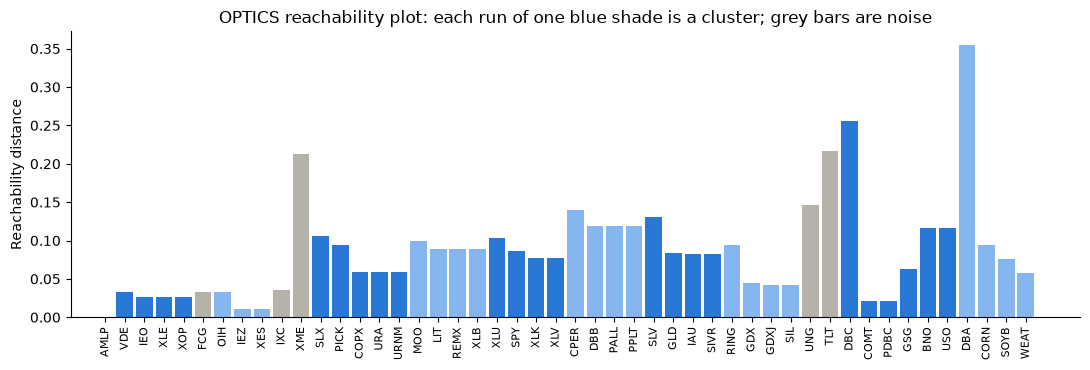

In [32]:
order = optics.ordering_
reach = optics.reachability_[order]
reach[np.isinf(reach)] = np.nan
lab = optics_labels[order]
tick = features.index[order]

# Alternate dark/light blue between consecutive clusters so you can see where each one starts
cluster_shade, shade, prev = [], 0, None
for l in lab:
    if l != -1 and l != prev:
        shade, prev = 1 - shade, l
    cluster_shade.append(NOISE_COLOR if l == -1 else ("#2a78d6" if shade else "#86b6ef"))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(range(len(reach)), reach, width=0.85, color=cluster_shade)
ax.set_xticks(range(len(reach)), tick, rotation=90, fontsize=8)
ax.set_ylabel("Reachability distance")
ax.set_title("OPTICS reachability plot: each run of one blue shade is a cluster; grey bars are noise")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Part 4. What did the clusters find?

### 4a. Visual representation of the different methods

Our points live in 5 dimensions, which we can't draw. **t-SNE** squashes them to 2D while trying to keep close points close (the paper does the same, Fig. 8). The distances in **t-SNE** are not the same so it's simply for a visual comparison.

Each dot is an ETF, **coloured by its category**, with the ticker written next to it. Boxes group the ETFs in each cluster. Look for:
- clusters that are all one colour (the method rediscovered a sector on its own), and
- clusters that **mix colours**: relationships a sector-based search would never test. 

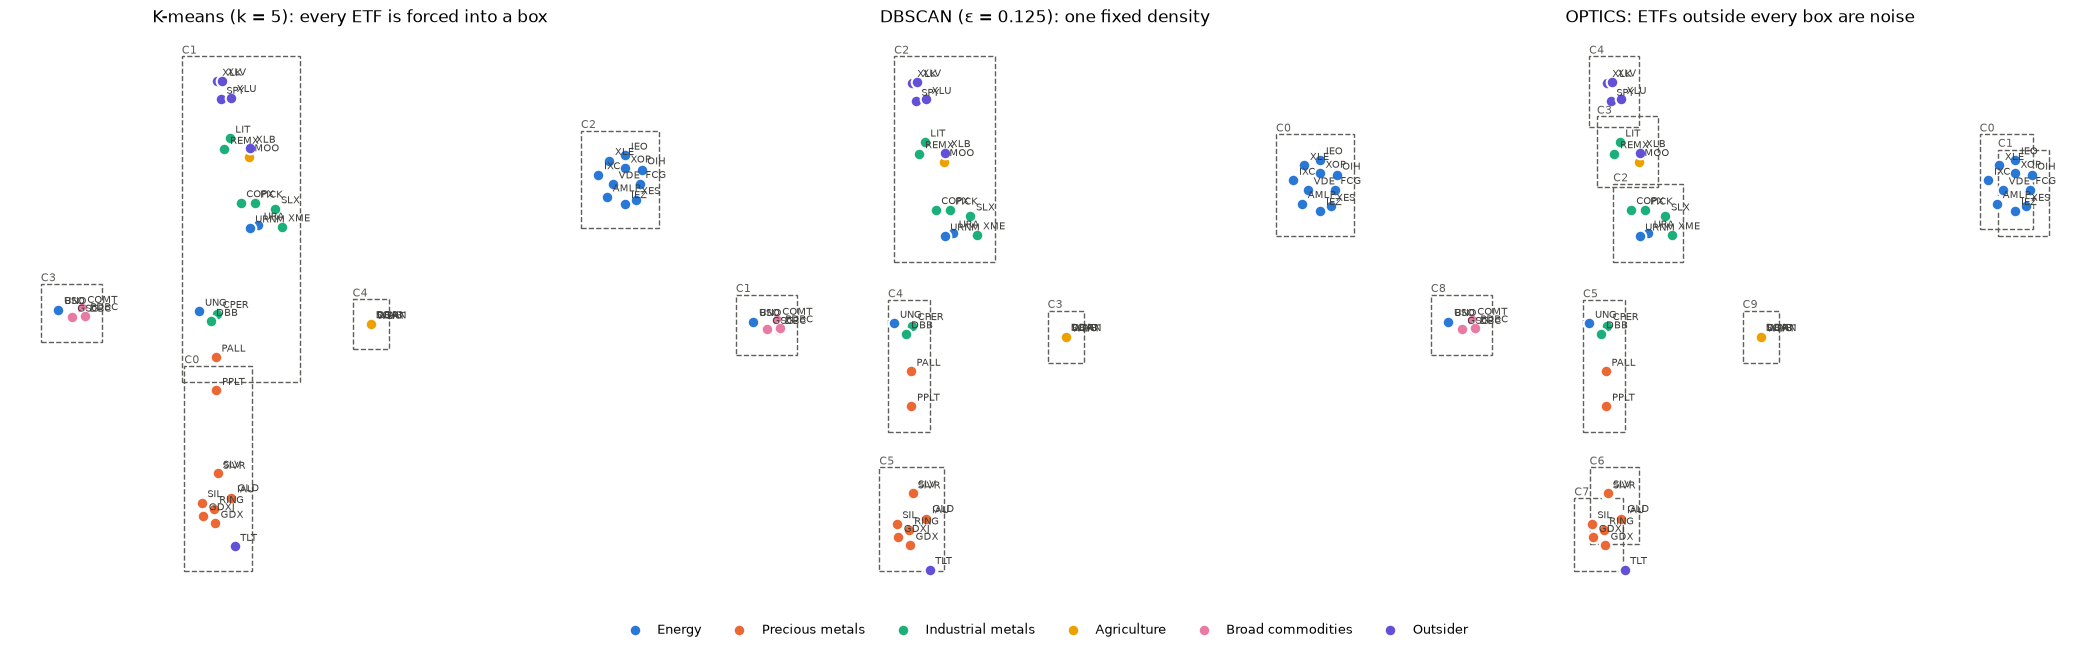

In [33]:
coords = TSNE(n_components=2, perplexity=min(10, len(X) - 1),
              random_state=RANDOM_STATE, init="pca").fit_transform(X)
coords = pd.DataFrame(coords, index=features.index, columns=["x", "y"])

def cluster_picture(labels, title, ax):
    for cat, col in CATEGORY_COLORS.items():
        pts = coords[categories == cat]
        if len(pts):
            ax.scatter(pts.x, pts.y, s=70, color=col, label=cat,
                       edgecolor="white", linewidth=1.5, zorder=3)
    for t, (x, y) in coords.iterrows():
        ax.annotate(t, (x, y), xytext=(4, 4), textcoords="offset points",
                    fontsize=7, color="#3d3d3a")
    pad = 0.03 * (coords.max() - coords.min()).max()      # box margin: 3% of the plot size
    for c in sorted(set(labels) - {-1}):
        pts = coords[labels == c]
        ax.add_patch(plt.Rectangle((pts.x.min() - pad, pts.y.min() - pad),
                                   pts.x.max() - pts.x.min() + 2 * pad,
                                   pts.y.max() - pts.y.min() + 2 * pad,
                                   fill=False, ec="#5f5e5a", lw=1, ls="--", zorder=1))
        ax.text(pts.x.min() - pad, pts.y.max() + pad, f"C{c}", fontsize=8,
                color="#5f5e5a", va="bottom")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
cluster_picture(kmeans_labels, f"K-means (k = {best_k}): every ETF is forced into a box", axes[0])
cluster_picture(dbscan_labels, f"DBSCAN (ε = {dbscan_eps:.3f}): one fixed density", axes[1])
cluster_picture(optics_labels, "OPTICS: ETFs outside every box are noise", axes[2])
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=len(names), frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

### 4b. Checking cluster members

The table lists every OPTICS cluster with its ETFs and their categories.
When choosing ETFs, we mostly chose commodity-linked ETFs, by listing all the ETFs in each cluster in the table below, it allows us to check that the clustering worked the way we expected. For exampel:
- both the ETFs linked to physical gold (GLD and IAU) are in the same cluster, same thing for physical silver (SIVR, SLV). This is like a sanity check to make sure that nothing went very wrong in the process of clustering. 
- We can also check which clusters contain **more than one category**, and whether these correlations are explainable.  (e.g. gold miners vs silver miners, oil producers vs oil services)
- Finally, we must check that the indexes we added (SPY, TLT, XLK, ...) are considered noise or outsiders as they are not commodity backed liked the other ETFs we chose. If they end up in a cluster with the other ETFs, we know that something went wrong in the clustering process. 

In [34]:
def describe_clusters(labels):
    rows = []
    for c in sorted(set(labels)):
        members = features.index[labels == c]
        rows.append({
            "cluster": "noise" if c == -1 else f"C{c}",
            "size": len(members),
            "categories": ", ".join(sorted(categories[members].unique())),
            "ETFs": ", ".join(members),
        })
    return pd.DataFrame(rows).set_index("cluster")

pd.set_option("display.max_colwidth", None)
print("OPTICS clusters")
describe_clusters(optics_labels)

OPTICS clusters


,size,categories,ETFs
cluster,,,
noise,5,"Energy, Industrial metals, Outsider","FCG, IXC, TLT, UNG, XME"
C0,5,Energy,"AMLP, IEO, VDE, XLE, XOP"
C1,3,Energy,"IEZ, OIH, XES"
C2,5,"Energy, Industrial metals","COPX, PICK, SLX, URA, URNM"
C3,4,"Agriculture, Industrial metals, Outsider","LIT, MOO, REMX, XLB"
C4,4,Outsider,"SPY, XLK, XLU, XLV"
C5,4,"Industrial metals, Precious metals","CPER, DBB, PALL, PPLT"
C6,4,Precious metals,"GLD, IAU, SIVR, SLV"
C7,4,Precious metals,"GDX, GDXJ, RING, SIL"


In [35]:
print("K-means clusters")
describe_clusters(kmeans_labels)

K-means clusters


,size,categories,ETFs
cluster,,,
C0,10,"Outsider, Precious metals","GDX, GDXJ, GLD, IAU, PPLT, RING, SIL, SIVR, SLV, TLT"
C1,18,"Agriculture, Energy, Industrial metals, Outsider, Precious metals","COPX, CPER, DBB, LIT, MOO, PALL, PICK, REMX, SLX, SPY, UNG, URA, URNM, XLB, XLK, XLU, XLV, XME"
C2,10,Energy,"AMLP, FCG, IEO, IEZ, IXC, OIH, VDE, XES, XLE, XOP"
C3,6,"Broad commodities, Energy","BNO, COMT, DBC, GSG, PDBC, USO"
C4,4,Agriculture,"CORN, DBA, SOYB, WEAT"


In [36]:
print("DBSCAN clusters")
describe_clusters(dbscan_labels)

DBSCAN clusters


,size,categories,ETFs
cluster,,,
noise,2,"Energy, Outsider","TLT, UNG"
C0,10,Energy,"AMLP, FCG, IEO, IEZ, IXC, OIH, VDE, XES, XLE, XOP"
C1,6,"Broad commodities, Energy","BNO, COMT, DBC, GSG, PDBC, USO"
C2,14,"Agriculture, Energy, Industrial metals, Outsider","COPX, LIT, MOO, PICK, REMX, SLX, SPY, URA, URNM, XLB, XLK, XLU, XLV, XME"
C3,4,Agriculture,"CORN, DBA, SOYB, WEAT"
C4,4,"Industrial metals, Precious metals","CPER, DBB, PALL, PPLT"
C5,8,Precious metals,"GDX, GDXJ, GLD, IAU, RING, SIL, SIVR, SLV"


### 4c. How many pairs would each method test?

To compare the methods efficiency we can look at how many pairs the alogrithm has to test to identify valuable pairs for trading. You can see that OPTICS has significantly cut the processing volume by clustering and disregarding outliers.

In [37]:
tickers = list(features.index)

def pairs_within(groups):
    # all pairs of ETFs that share a group label (noise label -1 never forms pairs)
    out = []
    for g in set(groups) - {-1}:
        members = [t for t, gi in zip(tickers, groups) if gi == g]
        out += list(combinations(sorted(members), 2))
    return out

candidates = {
    "All pairs":     list(combinations(sorted(tickers), 2)),
    "Same category": pairs_within(list(categories[tickers])),
    "K-means":       pairs_within(list(kmeans_labels)),
    "DBSCAN":        pairs_within(list(dbscan_labels)),
    "OPTICS":        pairs_within(list(optics_labels)),
}

summary = pd.DataFrame({
    "groups": [1, categories.nunique(), best_k, dbscan_n_clusters, n_clusters],
    "ETFs used": [len(tickers), len(tickers), len(tickers),
                  len(tickers) - dbscan_n_noise, len(tickers) - n_noise],
    "candidate pairs": [len(v) for v in candidates.values()],
}, index=candidates.keys())
summary

,groups,ETFs used,candidate pairs
All pairs,1,48,1128
Same category,6,48,209
K-means,5,48,264
DBSCAN,6,46,191
OPTICS,10,43,74


---
## Part 5. Filtering the pairs

Being in the same cluster only means two ETFs *react to the same factors*. It doesn't mean their spread will mean-revert in a tradeable way. Following the paper (Section III-C), a pair is kept only if it passes **all four** tests, run on the formation window only:

| # | Test | Why |
|---|---|---|
| 1 | **Cointegrated** (Engle-Granger p-value < 0.05) | The spread must return to a mean. Same `coint()` as the pairs trading notebook. The paper runs it **both ways round** (Y on X and X on Y) and keeps the stronger result, because the test depends on which asset you put first. (reference Pairs trading notebook)|
| 2 | **0 ≤ Hurst exponent < 0.5** | A second, independent check of mean reversion. $H < 0.5$: mean-reverting. $H = 0.5$: random walk. $0.5<H≤1$: trending. |
| 3 | **Half-life between 1 day and 1 year** | This calculates the half life of mean reversion, which allows us to approximate the holding period. If too short, the trading costs eat the profit; if too slow and money sits in a trade for too long. |
| 4 | **The pair's spread crosses its mean at least 12 times a year** | About one trading opportunity per month. A spread that reverts but rarely crosses gives too few trades. (this is the threshold the paper uses) |

The tests use **log prices**.

### Hurst Exponent

A measure of long-term memory in a time-series (how likely past trends are to influence future direction). 

| $H$ value | What it means |
|---|---|
| $H$ < 0.5 | **Mean-reverting**. The series keeps getting pulled back to its mean. This is what we want for a spread. |
| $H$ = 0.5 | **Random walk**. No memory, the past tells you nothing about the future. |
| $H$ > 0.5 | **Trending**. The change grows faster, because it tends to continue in the same direction. Bad for pairs since the spread would keep widening. |

**Calculation**

Take the spread data of two ETFs over the formation window (in our case 750 days). We split the data into different sized "chunks" by looking at the change in spread over a certain time gap. Starting with $n = 2$ days, compute every $n$-day change in the spread:
$$s_3 - s_1, s_4 - s_2,... $$
up to the end of the data. This gives us about $750-n$ changes.

We then take $\tau(n)$ as the standard deviation of this data, showing us how much the spread typically moves over $n$-days. Repeating the previous steps for every gap between 2 and 99 (99 because it stays within the typical trading horizon and keeps $\tau(n)$ reliable). We end up with 98 pairs: 
$$(2, \tau(2)), (3, \tau(3)), ... , (99, \tau(99)) $$

Taking the log of both, turning the pair into $(log(n), \tau(n))$, we fit an OLS line through the 98 points.

The slope of that line is H. The model is
$$\tau(n) \approx C • n^H $$
where $C$ is a scale constant (typically the size of a 1-day change in spread), and taking its log gives
$$log(\tau) = log(C) + H•log (n)$$

In [39]:
from statsmodels.tsa.stattools import coint

log_form = np.log(prices.loc[form_slice])
YEARS = len(log_form) / 252

def hurst(series, max_lag=100):
    # How fast does the typical change grow with the time gap?
    # Random walk: std of an n-day change grows like n^0.5 -> H = 0.5.
    # Mean-reverting: grows more slowly -> H < 0.5.
    lags = np.arange(2, max_lag)
    tau = [np.std(series[lag:] - series[:-lag]) for lag in lags]
    return np.polyfit(np.log(lags), np.log(tau), 1)[0]

def half_life(spread):
    # Same OU regression as the pairs trading notebook: s_{t+1} = a + b s_t
    b, a = np.polyfit(spread[:-1], spread[1:], 1)
    return -np.log(2) / np.log(b) if 0 < b < 1 else np.inf    # in trading days

def test_pair(t1, t2):
    p1, p2 = log_form[t1].values, log_form[t2].values
    # 1. Engle-Granger both ways round; keep the more negative t-statistic
    stat_a, p_a, _ = coint(p1, p2)
    stat_b, p_b, _ = coint(p2, p1)
    if stat_a <= stat_b:
        y_t, x_t, p_value = t1, t2, p_a
    else:
        y_t, x_t, p_value = t2, t1, p_b
    y, x = log_form[y_t].values, log_form[x_t].values
    beta1, beta0 = np.polyfit(x, y, 1)
    s = y - beta0 - beta1 * x
    crossings = np.sum(np.diff(np.sign(s - s.mean())) != 0) / YEARS
    return {"y": y_t, "x": x_t, "beta0": beta0, "beta1": beta1,
            "p_value": p_value, "hurst": hurst(s), "half_life": half_life(s),
            "crossings_per_year": crossings}

# Test every candidate pair once (the "All pairs" set contains all the others)
tested = pd.DataFrame([dict(pair=pr, **test_pair(*pr)) for pr in candidates["All pairs"]]).set_index("pair")

tested["passes"] = ((tested.p_value < 0.05) & (tested.hurst < 0.5)
                    & tested.half_life.between(1, 252) & (tested.crossings_per_year >= 12))
print(f"Tested {len(tested)} pairs, {tested.passes.sum()} pass all four filters.")

Tested 1128 pairs, 143 pass all four filters.


In [40]:
rows = {}
for method, prs in candidates.items():
    t = tested.loc[prs] if prs else tested.iloc[:0]
    rows[method] = {
        "candidate pairs": len(t),
        "1. cointegrated": int((t.p_value < 0.05).sum()),
        "selected (all 4)": int(t.passes.sum()),
        "selected / candidates": f"{t.passes.mean():.1%}" if len(t) else "-",
    }
pd.DataFrame(rows).T

,candidate pairs,1. cointegrated,selected (all 4),selected / candidates
All pairs,1128,180,143,12.7%
Same category,209,48,32,15.3%
K-means,264,54,42,15.9%
DBSCAN,191,48,36,18.8%
OPTICS,74,21,15,20.3%


**Questions to answer:**
- What share of *All pairs* gets selected compared with *OPTICS*? A higher hit rate inside clusters suggests clustering is pointing us at real relationships.
- Did GLD/IAU survive? Duplicates usually fail the **half-life** filter: their spread is tiny noise that "reverts" in under a day, so there's nothing to trade after costs. If they pass, remove them by hand and say why on a slide.
- Which selected pairs are **cross-category**? Those are pairs a sector-based search would have missed.

Next we save the selected pairs. Friday's backtest reads this file and trades them on 2023 (validation) and 2024 (test).

In [21]:
selected = []
for method, prs in candidates.items():
    t = tested.loc[prs] if prs else tested.iloc[:0]
    t = t[t.passes].reset_index().assign(method=method)
    selected.append(t)
selected = pd.concat(selected, ignore_index=True)
selected["category_y"] = selected.y.map(UNIVERSE)
selected["category_x"] = selected.x.map(UNIVERSE)
selected["cross_category"] = selected.category_y != selected.category_x

selected.drop(columns="pair").to_csv("selected_pairs.csv", index=False)
print(f"Saved {len(selected)} rows to selected_pairs.csv")
selected[selected.method == "OPTICS"].drop(columns=["pair", "method"]).round(3)

Saved 232 rows to selected_pairs.csv


,y,x,beta0,beta1,p_value,hurst,half_life,crossings_per_year,passes,category_y,category_x,cross_category
217,AMLP,IEO,0.668,0.612,0.003,0.301,27.504,13.667,True,Energy,Energy,False
218,AMLP,VDE,0.040,0.723,0.021,0.307,32.071,14.333,True,Energy,Energy,False
219,AMLP,XLE,0.714,0.744,0.047,0.326,37.026,14.333,True,Energy,Energy,False
220,AMLP,XOP,0.244,0.641,0.001,0.282,22.722,12.333,True,Energy,Energy,False
221,IEZ,OIH,-2.340,0.940,0.019,0.498,27.529,13.333,True,Energy,Energy,False
222,URNM,URA,-0.442,1.319,0.032,0.271,11.418,25.000,True,Energy,Energy,False
223,XLK,SPY,-2.879,1.193,0.037,0.398,29.807,19.333,True,Outsider,Outsider,False
224,BNO,COMT,-1.798,1.618,0.005,0.307,22.155,18.667,True,Energy,Broad commodities,True
225,BNO,DBC,-1.019,1.417,0.001,0.345,29.778,16.667,True,Energy,Broad commodities,True
226,BNO,GSG,-0.944,1.401,0.003,0.292,17.929,17.333,True,Energy,Broad commodities,True
